Karena Google Colab memiliki keterbatasan hardware dibandingkan superkomputer sungguhan, studi kasus ini akan mensimulasikan Konsep Dasar HPC menggunakan CPU multi-core yang ada di server Colab. Kita akan mengambil tema Mitigasi Bencana Simulasi Risiko Banjir untuk menghubungkan komputasi dengan kebutuhan lokal, misalnya menganalisis potensi luapan sungai di wilayah rawan seperti Bengkulu.

Skenario:
Kita berperan sebagai "Integrator" yang diminta oleh pemerintah daerah untuk memetakan risiko banjir tahun depan. Cuaca sangat tidak menentu, sehingga kita harus membuat puluhan ribu skenario simulasi curah hujan. Memproses data ini satu per satu akan memakan waktu lama, sehingga kita harus menerapkan konsep distribusi beban kerja HPC ke beberapa core CPU sekaligus.

Memulai perhitungan 20000 skenario cuaca...

>> Menjalankan Komputasi Serial (1 Core CPU)...
Waktu Serial Selesai : 26.73 detik

>> Menjalankan Komputasi Paralel (Membagi tugas ke banyak Core CPU)...
Waktu Paralel Selesai: 22.44 detik

--- HASIL HPC: Proses 1.19x LEBIH CEPAT! ---



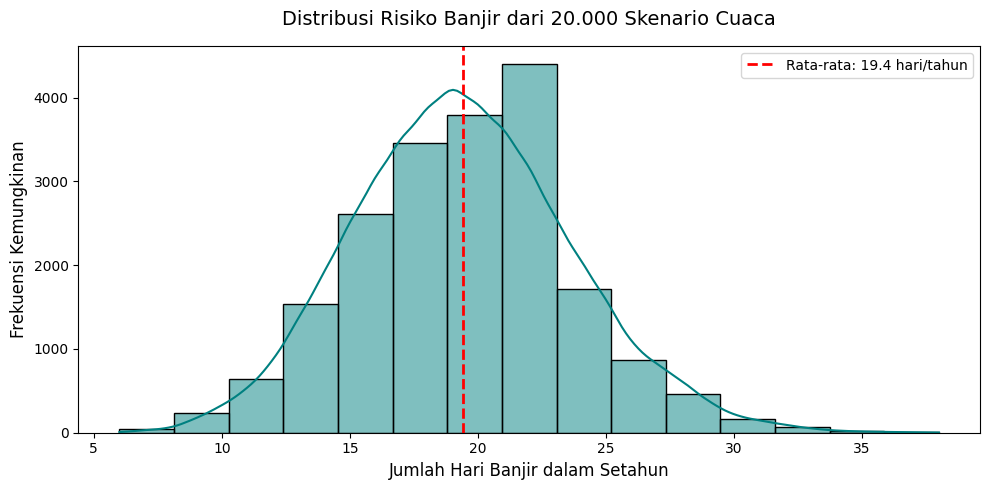

In [1]:
import numpy as np
import time
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import seaborn as sns


def hitung_risiko_banjir(seed):
    np.random.seed(seed)
    debit_harian = [np.random.normal(500, 150) + np.sin(i/10)*50 for i in range(365)]

    jumlah_banjir = sum(1 for debit in debit_harian if debit > 750)
    return jumlah_banjir

JUMLAH_SKENARIO = 20000

print(f"Memulai perhitungan {JUMLAH_SKENARIO} skenario cuaca...\n")

print(">> Menjalankan Komputasi Serial (1 Core CPU)...")
start_serial = time.time()
hasil_serial = [hitung_risiko_banjir(i) for i in range(JUMLAH_SKENARIO)]
waktu_serial = time.time() - start_serial
print(f"Waktu Serial Selesai : {waktu_serial:.2f} detik\n")


print(">> Menjalankan Komputasi Paralel (Membagi tugas ke banyak Core CPU)...")
start_paralel = time.time()
hasil_paralel = Parallel(n_jobs=-1)(delayed(hitung_risiko_banjir)(i) for i in range(JUMLAH_SKENARIO))
waktu_paralel = time.time() - start_paralel
print(f"Waktu Paralel Selesai: {waktu_paralel:.2f} detik")

speedup = waktu_serial / waktu_paralel
print(f"\n--- HASIL HPC: Proses {speedup:.2f}x LEBIH CEPAT! ---\n")


plt.figure(figsize=(10, 5))
sns.histplot(hasil_paralel, bins=15, kde=True, color='teal')
plt.title('Distribusi Risiko Banjir dari 20.000 Skenario Cuaca', fontsize=14, pad=15)
plt.xlabel('Jumlah Hari Banjir dalam Setahun', fontsize=12)
plt.ylabel('Frekuensi Kemungkinan', fontsize=12)

rata_rata = np.mean(hasil_paralel)
plt.axvline(rata_rata, color='red', linestyle='dashed', linewidth=2,
            label=f'Rata-rata: {rata_rata:.1f} hari/tahun')

plt.legend()
plt.tight_layout()
plt.show()

kesimpulan khusus dari studi kasus komputasi serial vs paralel menggunakan CPU:

Pembuktian Efisiensi Waktu: Simulasi secara langsung membuktikan bahwa mendistribusikan beban kerja ke beberapa core CPU memangkas waktu pemrosesan secara signifikan dibandingkan memprosesnya satu per satu. Dalam mitigasi bencana nyata, penghematan waktu komputasi ini sangat krusial agar keputusan pencegahan dapat diambil lebih cepat sebelum banjir benar-benar terjadi.

Fungsi Manusia sebagai Integrator: Komputer hanya menjalankan instruksi matematika. Peran Anda sebagai pembuat kode adalah menerjemahkan masalah lokal menjadi model simulasi probabilitas agar mesin bisa memberikan insight yang relevan untuk kebijakan daerah.

Tuntutan Keterampilan SDM: Studi kasus ini menyoroti perlunya pergeseran cara berpikir mahasiswa informatika. Menguasai pemrograman dasar tidak lagi cukup; Anda harus mulai membiasakan diri menulis kode dengan arsitektur paralel agar siap memanfaatkan ekosistem High-Performance Computing atau superkomputer di masa depan.